# HMDA 2024: thí nghiệm hiệu năng Pandas và PySpark (rules.yaml mục 17, 18)

Theo nhận xét của thầy cho nhóm 9: các bản nhân ×2, ×4, ×8 **chỉ dùng cho benchmark**; ghi lại **RAM cao nhất** và
**thời điểm Pandas hết bộ nhớ**.

Thiết kế:
- Bảng đo `perf_core`: mẫu core đã làm sạch, đúng kiểu, có sẵn p_ext (tạo một lần, không tính giờ).
- Kích thước: 10%, 25%, 50%, 100% (theo bucket hash của `row_id`), rồi ×2, ×4, ×8 (bản sao, `row_id + j·10^8`).
- Workload: W0 đọc CSV gốc 99 cột; W1 groupBy loan_type × purpose; W2 groupBy county; W3 join TS, O/E theo lender,
  xếp hạng bằng window, 10 vòng hiệu ứng hai chiều.
- Mỗi cặp (engine, kích thước) chạy trong **tiến trình con riêng**. Tiến trình cha lấy mẫu RSS mỗi 0,2 giây (cộng cả
  JVM của Spark). Vượt 90% RAM máy thì dừng tiến trình con và ghi là hết bộ nhớ, kèm giai đoạn đang chạy.
- Pandas: đo riêng thời gian nạp (load) và thời gian tính (warm); cold = load + warm.
  Spark: đo riêng khởi tạo SparkSession, chế độ không cache (đọc Parquet mỗi lần) và có cache (đo riêng thời gian dựng cache).
- Mỗi phép đo: 1 lần làm nóng + 5 lần đo, lấy trung vị (kèm min, max).

Chạy trên Kaggle: Add Input gồm `hmda-2024-one-year-raw` (Parquet), `hmda-config` (`rules.yaml`, `expected.yaml`) và
`hmda-2024-ffiec-files` (CSV gốc One-Year và Transmittal Sheet, nhập từ link FFIEC). W0 đọc đúng CSV gốc đó; nếu không có
trong Input và không có Internet, notebook ghi lại CSV từ Parquet và đánh dấu `w0_source` trong kết quả.

In [1]:
# ===== 0. Cài đặt =====
import os, sys, glob, json, time, math, shutil, subprocess, platform, textwrap, zipfile, urllib.request
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
import yaml
import matplotlib

try:
    get_ipython  # noqa: F821
    IN_NOTEBOOK = True
except NameError:
    IN_NOTEBOOK = False
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

try:
    import psutil
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "psutil"], check=True); import psutil
try:
    import pyspark  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark"], check=True)


def find_file(pattern, required=True):
    roots = [os.environ["HMDA_INPUT"]] if os.environ.get("HMDA_INPUT") else ["/kaggle/input"]
    hits = sorted(h for r_ in roots for h in glob.glob(os.path.join(r_, "**", pattern), recursive=True))
    assert hits or not required, f"Không thấy {pattern} trong {roots}"
    return hits[0] if hits else None


RAW_SRC = find_file("hmda_2024_raw.parquet")
R = yaml.safe_load(open(find_file("rules.yaml"), encoding="utf-8"))
assert float(R["version"]) >= 1.1
TS_PATH = find_file("*public_ts*.csv", required=False) or find_file("*public_ts*.zip", required=False)
OUTROOT = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.environ.get("HMDA_OUT", "output")
RES, FIG = f"{OUTROOT}/results/perf", f"{OUTROOT}/figures/perf"
WORK = os.environ.get("HMDA_WORK", "/tmp/hmda_perf")
for d in (RES, FIG, WORK, f"{WORK}/data", f"{WORK}/logs"):
    os.makedirs(d, exist_ok=True)
PF = R["performance"]
WARMUP, RUNS = int(os.environ.get("PERF_WARMUP", PF["warmup_runs"])), int(os.environ.get("PERF_RUNS", PF["timed_runs"]))
def container_ram_bytes():
    """RAM dùng được: min(RAM máy, giới hạn cgroup của container) vì Kaggle giới hạn bằng cgroup (30 GiB)."""
    tot = psutil.virtual_memory().total
    for p_ in ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory/memory.limit_in_bytes"):
        try:
            v_ = open(p_).read().strip()
            if v_.isdigit():
                tot = min(tot, int(v_))
        except OSError:
            pass
    return tot


TOTAL_RAM = container_ram_bytes()
BUDGET = float(os.environ.get("PERF_BUDGET_GB", PF["memory"]["budget_share_of_ram"] * TOTAL_RAM / 1e9)) * 1e9
SIZES = os.environ.get("PERF_SIZES", ",".join(PF["sizes"])).split(",")
ENV = {"python": sys.version.split()[0], "platform": platform.platform(), "cpu_logical": os.cpu_count(),
       "ram_total_gb": round(TOTAL_RAM / 1e9, 1), "memory_budget_gb": round(BUDGET / 1e9, 1), "pandas": pd.__version__,
       "pyarrow": pa.__version__, "pyspark": __import__("pyspark").__version__, "rules_version": str(R["version"])}
if TS_PATH and TS_PATH.endswith(".zip"):
    with zipfile.ZipFile(TS_PATH) as z_:
        nm_ = [n for n in z_.namelist() if n.lower().endswith((".csv", ".txt"))][0]
        TS_PATH = z_.extract(nm_, WORK)
print(json.dumps(ENV, indent=1)); print("TS:", TS_PATH)

{
 "python": "3.13.18",
 "platform": "Linux-6.18.55+-x86_64-with-glibc2.39",
 "cpu_logical": 4,
 "ram_total_gb": 32.2,
 "memory_budget_gb": 29.0,
 "pandas": "2.3.3",
 "pyarrow": "23.0.1",
 "pyspark": "4.0.4",
 "rules_version": "1.1"
}
TS: /kaggle/input/datasets/quangvinh7105/hmda-2024-ffiec-files/2024_public_ts_one_year_csv/2024_public_ts_one_year_csv.csv


## 1. Tạo bảng đo `perf_core` và các kích thước (không tính giờ)
Cùng định nghĩa với hai notebook phân tích: lọc core, usable, ô rủi ro 6 × 5 × 3, p_ext theo ô mở rộng (fallback ô rủi ro).

In [2]:
t0 = time.time()
V, D, L = R["variables"], R["variables"]["debt_to_income_ratio"], R["variables"]["combined_loan_to_value_ratio"]
FILT = R["samples"]["core_filters"]
cols = sorted({f["column"] for f in FILT} | {"row_id", "lei", "state_code", "county_code", "derived_msa_md", "action_taken",
                                             "loan_type", "loan_purpose", "loan_amount", "income", "debt_to_income_ratio",
                                             "combined_loan_to_value_ratio"})
parts = []
for b in pq.ParquetFile(RAW_SRC).iter_batches(batch_size=500_000, columns=cols):
    tb = pa.Table.from_batches([b])
    for f in FILT:
        col = tb[f["column"]]
        tb = tb.filter(pc.is_in(col, pa.array(f["in"])) if "in" in f else pc.equal(col, f["equals"]))
    parts.append(tb)
c = pa.concat_tables(parts).to_pandas(); del parts


def num(s):
    return pd.to_numeric(s.where(~s.isin(["NA", "Exempt", ""])), errors="coerce")


def cut(x, spec, cuts=None):
    rs = lambda v: cuts[v] if isinstance(v, str) else float(v)
    return pd.cut(x, [rs(spec[0]["lo"])] + [rs(b_["hi"]) for b_ in spec], labels=[b_["label"] for b_ in spec], right=True)


dti = c["debt_to_income_ratio"].str.replace("%", "", regex=False).str.replace(" ", "", regex=False).map(
    {str(k): v for k, v in D["ordinal_map"].items()})
cltv, inc, amt = num(c["combined_loan_to_value_ratio"]), num(c["income"]), num(c["loan_amount"])
cltv_ok = (cltv > L["valid_range"]["gt"]) & (cltv <= L["valid_range"]["le"])
P = pd.DataFrame({
    "row_id": c["row_id"].astype("int64"), "lei": c["lei"], "state_code": c["state_code"], "county_code": c["county_code"],
    "msa": c["derived_msa_md"], "action_taken": c["action_taken"].astype("int8"), "loan_type": c["loan_type"].astype("int8"),
    "loan_purpose": c["loan_purpose"].astype("int16"), "loan_amount": amt})
P["county_valid"] = P["county_code"].str.fullmatch(R["geography"]["county_code_format"].strip("^$")).fillna(False)
P["decisioned"] = P["action_taken"].isin([1, 2, 3]); P["denied"] = P["action_taken"] == 3
P["usable"] = P["decisioned"] & dti.notna() & cltv_ok & (inc > 0)
P["y"] = P["denied"].astype("float64")
lti = np.where(inc > 0, amt / (1000 * inc), np.nan)
B = pd.DataFrame({"d": cut(dti, D["bands"]), "c": cut(cltv.where(cltv_ok), L["bands"]),
                  "l": cut(pd.Series(lti), V["loan_to_income"]["bands"], V["loan_to_income"]["cut_exact"]),
                  "t": P["loan_type"], "p": P["loan_purpose"], "y": P["y"]})[P["usable"].to_numpy()]
g_ = B.groupby(["d", "c", "l", "t", "p"], observed=True)["y"]
pe = np.where(g_.transform("size") >= R["extended_cells"]["min_n"], g_.transform("mean"),
              B.groupby(["d", "c", "l"], observed=True)["y"].transform("mean"))
P["p_ext"] = np.nan
P.loc[P["usable"].to_numpy(), "p_ext"] = pe
P = P[PF["columns"]]
del c, B, g_, dti, cltv, inc, amt
S_ = R["sampling"]
bucket = ((P["row_id"] * S_["hash_multiplier"]) % S_["hash_modulus"]) % S_["buckets"]
DATA = {}
for sz in SIZES:
    path = f"{WORK}/data/{sz.replace('%', 'pct')}"
    if os.path.exists(path):
        shutil.rmtree(path)
    os.makedirs(path)
    if sz.endswith("%"):
        sub = pa.Table.from_pandas(P[bucket < int(sz[:-1])], preserve_index=False)
        pq.write_table(sub, f"{path}/part-0.parquet"); rows = sub.num_rows
    else:
        k = int(sz[1:]); base = pa.Table.from_pandas(P, preserve_index=False)
        for j in range(k):
            pq.write_table(base.set_column(base.schema.get_field_index("row_id"), "row_id",
                                           pc.add(base["row_id"], j * S_["replicas"]["row_id_offset"])), f"{path}/part-{j}.parquet")
        rows = base.num_rows * k
    DATA[sz] = {"path": path, "rows": int(rows), "disk_mb": round(sum(os.path.getsize(f) for f in glob.glob(f"{path}/*")) / 1e6, 1)}
del P, bucket
json.dump(DATA, open(f"{WORK}/data/sizes.json", "w"))
print(pd.DataFrame(DATA).T.to_string()); print(f"chuẩn bị dữ liệu: {time.time() - t0:.0f}s")

                            path      rows disk_mb
10%    /tmp/hmda_perf/data/10pct    576771     6.6
25%    /tmp/hmda_perf/data/25pct   1443465    16.1
50%    /tmp/hmda_perf/data/50pct   2887345    31.7
100%  /tmp/hmda_perf/data/100pct   5775325    63.2
x2        /tmp/hmda_perf/data/x2  11550650   126.4
x4        /tmp/hmda_perf/data/x4  23101300   252.8
x8        /tmp/hmda_perf/data/x8  46202600   505.5
chuẩn bị dữ liệu: 136s


## 2. Nguồn cho W0: file CSV gốc
Ưu tiên tải đúng file One-Year CSV từ FFIEC (cần bật Internet). Không tải được thì ghi lại CSV từ Parquet (cùng dữ liệu,
khác cách đặt dấu ngoặc kép) và ghi rõ `w0_source` trong kết quả.

In [3]:
W0_CSV, W0_SOURCE = None, None
URL = "https://files.ffiec.cfpb.gov/static-data/one-year/2024/2024_public_lar_one_year_csv.zip"
LAR_IN = find_file("*public_lar_one_year*.csv", required=False) or find_file("*public_lar_one_year*.zip", required=False)
if os.environ.get("PERF_SKIP_W0") != "1":
    try:
        if LAR_IN and LAR_IN.lower().endswith(".csv"):      # CSV gốc đã có trong Input: chép sang đĩa làm việc
            W0_CSV = f"{WORK}/{os.path.basename(LAR_IN)}"
            if not os.path.exists(W0_CSV) or os.path.getsize(W0_CSV) != os.path.getsize(LAR_IN):
                shutil.copy(LAR_IN, W0_CSV)
        else:
            zp = LAR_IN or f"{WORK}/lar.zip"
            if not os.path.exists(zp):
                urllib.request.urlretrieve(URL, zp)
            with zipfile.ZipFile(zp) as z_:
                nm_ = [n for n in z_.namelist() if n.lower().endswith(".csv")][0]
                W0_CSV = z_.extract(nm_, WORK)
            if not LAR_IN:
                os.remove(zp)
        W0_SOURCE = "original FFIEC CSV"
    except Exception as e:   # không có Internet và không có CSV gốc trong Input
        print("không tải được CSV gốc:", repr(e)[:120])
        W0_CSV = f"{WORK}/raw_from_parquet.csv"
        if not os.path.exists(W0_CSV):
            import pyarrow.csv as pacsv
            pf_ = pq.ParquetFile(RAW_SRC); names = [n for n in pf_.schema_arrow.names if n != "row_id"]
            with pacsv.CSVWriter(W0_CSV, pf_.schema_arrow.remove(pf_.schema_arrow.get_field_index("row_id"))) as w_:
                for b in pf_.iter_batches(batch_size=500_000, columns=names):
                    w_.write_batch(b)
        W0_SOURCE = "CSV rewritten from Parquet"
    print(W0_SOURCE, W0_CSV, round(os.path.getsize(W0_CSV) / 1e9, 2), "GB")
ENV["w0_source"] = W0_SOURCE

original FFIEC CSV /tmp/hmda_perf/2024_public_lar_one_year_csv.csv 4.64 GB


## 3. Mã của tiến trình con (worker) Pandas và Spark
Hai worker làm đúng một phép tính; mỗi worker ghi giai đoạn đang chạy vào `stage.txt` để khi bị dừng vì hết RAM,
tiến trình cha biết đang ở bước nào. Kết quả mỗi workload được lưu để so Pandas với Spark ở 100%.

In [4]:
COMMON = r'''
import json, os, sys, time
import numpy as np
ARGS = json.loads(sys.argv[1])
STAGE = ARGS["stage_file"]
def stage(s):
    with open(STAGE, "w") as f: f.write(s)
def timed(fn, warmup, runs, label):
    out = []
    for i in range(warmup + runs):
        stage(f"{label} run {i}")
        t = time.perf_counter(); res = fn(); dt = time.perf_counter() - t
        if i >= warmup: out.append(dt)
    return out, res
'''

PANDAS_WORKER = COMMON + r'''
import pandas as pd
A = ARGS; RESULT = {"engine": "pandas", "size": A["size"], "times": {}, "results": {}}
COLS = A["columns"]
if A["mode"] == "w0":
    def w0():
        if A["engine"] == "pyarrow":
            df = pd.read_csv(A["csv"], dtype=str, keep_default_na=False, engine="pyarrow", dtype_backend="pyarrow")
        else:
            df = pd.read_csv(A["csv"], dtype=str, keep_default_na=False, engine="c", low_memory=False)
        n = len(df); del df; return n
    RESULT["times"][f"W0_{A['engine']}"], RESULT["results"]["W0_rows"] = timed(w0, A["warmup"], A["runs"], f"W0 {A['engine']}")
else:
    def load():
        return pd.read_parquet(A["path"], columns=COLS)
    times = []
    for i in range(A["warmup"] + A["runs"]):
        stage(f"load run {i}"); t = time.perf_counter(); df = load(); dt = time.perf_counter() - t
        if i >= A["warmup"]: times.append(dt)
        if i < A["warmup"] + A["runs"] - 1: del df
    RESULT["times"]["load"] = times
    ts = pd.read_csv(A["ts"], dtype=str)[["lei", "agency_code"]].drop_duplicates("lei") if A["ts"] else None

    def w1():
        d = df[df["decisioned"]]
        g = d.groupby(["loan_type", "loan_purpose"]).agg(n=("y", "size"), rate=("y", "mean"), mean_amount=("loan_amount", "mean"))
        return g.reset_index().values.tolist()

    def w2():
        d = df[df["decisioned"] & df["county_valid"]]
        g = d.groupby("county_code").agg(n=("y", "size"), rate=("y", "mean"))
        return [len(g), float(g["rate"].sum()), int(g["n"].sum())]

    def w3():
        u = df[df["usable"]]
        lo = u.groupby("lei").agg(O=("y", "sum"), E=("p_ext", "sum")).reset_index()
        lo["agency_code"] = lo["lei"].map(ts.set_index("lei")["agency_code"]) if ts is not None else "NA"
        lo["agency_code"] = lo["agency_code"].fillna("NA")
        lo["oe"] = lo["O"] / lo["E"]
        lo = lo.sort_values(["agency_code", "oe", "lei"], ascending=[True, False, True])
        lo["rank"] = lo.groupby("agency_code").cumcount() + 1
        top = lo[lo["rank"] <= 3][["agency_code", "lei", "oe"]].values.tolist()
        cm = u[u["msa"] != "99999"]
        cells = cm.assign(r=cm["y"] - cm["p_ext"]).groupby(["lei", "msa"]).agg(n=("r", "size"), S=("r", "sum")).reset_index()
        b = pd.Series(0.0, index=cells["msa"].unique())
        for _ in range(A["iters"]):
            t_ = cells.assign(x=cells["S"] - cells["n"] * cells["msa"].map(b))
            a = t_.groupby("lei")["x"].sum() / t_.groupby("lei")["n"].sum()
            t_ = cells.assign(x=cells["S"] - cells["n"] * cells["lei"].map(a))
            b = t_.groupby("msa")["x"].sum() / t_.groupby("msa")["n"].sum()
        nl = cells.groupby("lei")["n"].sum(); nm = cells.groupby("msa")["n"].sum()
        def wsd(x, w):
            m = np.average(x, weights=w); return float(np.sqrt(np.average((x - m) ** 2, weights=w)))
        return {"top": top, "oe_sum": float(lo["oe"].sum()), "lender_sd": wsd(a[nl.index], nl), "msa_sd": wsd(b[nm.index], nm)}

    for name, fn in [("W1", w1), ("W2", w2), ("W3", w3)]:
        RESULT["times"][name], RESULT["results"][name] = timed(fn, A["warmup"], A["runs"], name)
stage("done")
json.dump(RESULT, open(A["out"], "w"), default=str)
'''

SPARK_WORKER = COMMON + r'''
A = ARGS; RESULT = {"engine": "spark", "size": A["size"], "times": {}, "results": {}}
stage("spark init")
t = time.perf_counter()
from pyspark.sql import SparkSession, functions as F, Window
spark = (SparkSession.builder.master("local[*]").appName("hmda-perf")
         .config("spark.driver.memory", f"{A['driver_gb']}g")
         .config("spark.sql.shuffle.partitions", str(A["shuffle_partitions"]))
         .config("spark.sql.ansi.enabled", "false")
         .config("spark.sql.csv.parser.columnPruning.enabled", "false")
         .config("spark.sql.constraintPropagation.enabled", "false")
         .config("spark.local.dir", A["local_dir"]).getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
RESULT["times"]["init"] = [time.perf_counter() - t]
if A["mode"] == "w0":
    def w0():
        return spark.read.option("header", True).csv(A["csv"]).count()
    RESULT["times"]["W0_spark"], RESULT["results"]["W0_rows"] = timed(w0, A["warmup"], A["runs"], "W0 spark")
else:
    ts = (spark.read.option("header", True).csv(A["ts"]).select("lei", "agency_code").dropDuplicates(["lei"]) if A["ts"] else None)

    def make(get):
        def w1():
            d = get().filter("decisioned")
            g = d.groupBy("loan_type", "loan_purpose").agg(F.count(F.lit(1)).alias("n"), F.avg("y").alias("rate"),
                                                          F.avg("loan_amount").alias("mean_amount"))
            return sorted([list(r) for r in g.collect()])

        def w2():
            d = get().filter("decisioned and county_valid")
            r = d.groupBy("county_code").agg(F.count(F.lit(1)).alias("n"), F.avg("y").alias("rate")) \
                 .agg(F.count(F.lit(1)), F.sum("rate"), F.sum("n")).first()
            return [r[0], float(r[1]), int(r[2])]

        def w3():
            u = get().filter("usable")
            lo = u.groupBy("lei").agg(F.sum("y").alias("O"), F.sum("p_ext").alias("E"))
            lo = (lo.join(F.broadcast(ts), "lei", "left") if ts is not None else lo.withColumn("agency_code", F.lit(None).cast("string")))
            lo = lo.withColumn("agency_code", F.coalesce("agency_code", F.lit("NA"))).withColumn("oe", F.col("O") / F.col("E"))
            lo = lo.withColumn("rank", F.row_number().over(Window.partitionBy("agency_code").orderBy(F.desc("oe"), "lei")))
            cells = (u.filter(F.col("msa") != "99999").withColumn("r", F.col("y") - F.col("p_ext"))
                      .groupBy("lei", "msa").agg(F.count(F.lit(1)).alias("n"), F.sum("r").alias("S")))
            b = cells.select("msa").distinct().withColumn("b", F.lit(0.0))
            cells = cells.localCheckpoint()   # bảng ô nhỏ; cắt lineage để vòng lặp không làm phình kế hoạch truy vấn
            for _ in range(A["iters"]):
                a = cells.join(F.broadcast(b), "msa").groupBy("lei").agg(
                    (F.sum(F.col("S") - F.col("n") * F.col("b")) / F.sum("n")).alias("a")).localCheckpoint()
                b = cells.join(F.broadcast(a), "lei").groupBy("msa").agg(
                    (F.sum(F.col("S") - F.col("n") * F.col("a")) / F.sum("n")).alias("b")).localCheckpoint()
            nl = cells.groupBy("lei").agg(F.sum("n").alias("w")); nm = cells.groupBy("msa").agg(F.sum("n").alias("w"))
            ea = a.join(nl, "lei").withColumn("k", F.lit("lender")).select("k", F.col("a").alias("e"), "w")
            eb = b.join(nm, "msa").withColumn("k", F.lit("msa")).select("k", F.col("b").alias("e"), "w")
            st = ea.unionByName(eb).groupBy("k").agg((F.sum(F.col("e") * F.col("w")) / F.sum("w")).alias("m"),
                                                     F.sum(F.col("e") * F.col("e") * F.col("w")).alias("s2"), F.sum("w").alias("sw"))
            top = lo.filter("rank <= 3").select("agency_code", "lei", "oe")
            out = {r["k"]: float(np.sqrt(max(r["s2"] / r["sw"] - r["m"] ** 2, 0))) for r in st.collect()}
            tl = sorted([list(r) for r in top.collect()])
            return {"top": tl, "oe_sum": float(lo.agg(F.sum("oe")).first()[0]), "lender_sd": out["lender"], "msa_sd": out["msa"]}
        return w1, w2, w3

    w1, w2, w3 = make(lambda: spark.read.parquet(A["path"]))
    for name, fn in [("W1", w1), ("W2", w2), ("W3", w3)]:
        RESULT["times"][f"{name}_nocache"], RESULT["results"][name] = timed(fn, A["warmup"], A["runs"], f"{name} no-cache")
    stage("cache build")
    base = spark.read.parquet(A["path"]).cache()
    t = time.perf_counter(); base.count(); RESULT["times"]["cache_build"] = [time.perf_counter() - t]
    w1, w2, w3 = make(lambda: base)
    for name, fn in [("W1", w1), ("W2", w2), ("W3", w3)]:
        RESULT["times"][f"{name}_cache"], _ = timed(fn, A["warmup"], A["runs"], f"{name} cache")
    base.unpersist()
spark.stop()
stage("done")
json.dump(RESULT, open(A["out"], "w"), default=str)
'''
open(f"{WORK}/pandas_worker.py", "w").write(PANDAS_WORKER)
open(f"{WORK}/spark_worker.py", "w").write(SPARK_WORKER)
print("đã ghi worker vào", WORK)

đã ghi worker vào /tmp/hmda_perf


## 4. Tiến trình cha: chạy từng worker, đo RAM cao nhất, phát hiện hết bộ nhớ

In [5]:
def tree_rss(p):
    tot = 0
    try:
        procs = [p] + p.children(recursive=True)
    except psutil.Error:
        return 0
    for q in procs:
        try:
            tot += q.memory_info().rss
        except psutil.Error:
            pass
    return tot


def run_worker(script, args, label):
    out = f"{WORK}/logs/{label}.json"; stage_f = f"{WORK}/logs/{label}.stage"; log_f = f"{WORK}/logs/{label}.log"
    for f in (out, stage_f):
        if os.path.exists(f):
            os.remove(f)
    args = {**args, "out": out, "stage_file": stage_f, "warmup": WARMUP, "runs": RUNS,
            "iters": PF["two_way_iterations_benchmark"], "columns": PF["columns"], "ts": TS_PATH}
    t0 = time.time(); peak = 0; status = "ok"
    with open(log_f, "w") as lf:
        proc = subprocess.Popen([sys.executable, script, json.dumps(args)], stdout=lf, stderr=subprocess.STDOUT)
        ps = psutil.Process(proc.pid)
        while proc.poll() is None:
            rss = tree_rss(ps); peak = max(peak, rss)
            if rss > BUDGET:
                status = "oom_budget"
                for q in ps.children(recursive=True) + [ps]:
                    try:
                        q.kill()
                    except psutil.Error:
                        pass
                break
            time.sleep(PF["memory"]["sampling_interval_s"])
        rc = proc.wait()
    tail = open(log_f, errors="ignore").read()[-3000:]
    if status == "ok" and rc != 0:
        status = "memory_error" if "MemoryError" in tail or "OutOfMemory" in tail else ("oom_killed" if rc in (-9, 137) else f"error_{rc}")
    st = open(stage_f).read() if os.path.exists(stage_f) else ""
    res = json.load(open(out)) if (status == "ok" and os.path.exists(out)) else None
    rec = {"label": label, "status": status, "peak_rss_gb": round(peak / 1e9, 3), "seconds": round(time.time() - t0, 1),
           "stage": st, "returncode": rc}
    print(f"  {label:<28} {status:<14} RAM cao nhất {peak / 1e9:6.2f} GB | {rec['seconds']:7.1f}s | giai đoạn cuối: {st}")
    if status.startswith("error"):
        print(tail[-1500:])
    return rec, res


MEM, RESULTS = [], []
DRIVER_GB = max(2, int(TOTAL_RAM / 1e9 * 0.6))
SPARK_ARGS = {"driver_gb": DRIVER_GB, "shuffle_partitions": max(8, 2 * (os.cpu_count() or 2)), "local_dir": f"{WORK}/spark_local"}

print("W0, đọc CSV gốc 99 cột:")
if W0_CSV:
    for eng in ["pyarrow", "c"]:
        rec, res = run_worker(f"{WORK}/pandas_worker.py", {"mode": "w0", "engine": eng, "csv": W0_CSV, "size": "W0", "path": None},
                              f"pandas_W0_{eng}")
        MEM.append({**rec, "engine": f"pandas_{eng}", "size": "W0", "rows": None}); RESULTS.append(res)
    rec, res = run_worker(f"{WORK}/spark_worker.py", {**SPARK_ARGS, "mode": "w0", "csv": W0_CSV, "size": "W0", "path": None}, "spark_W0")
    MEM.append({**rec, "engine": "spark", "size": "W0", "rows": None}); RESULTS.append(res)

print("Pandas theo kích thước (dừng sau lần hết bộ nhớ đầu tiên):")
pandas_oom = False
for sz in SIZES:
    if pandas_oom and PF["memory"]["stop_pandas_after_first_oom"]:
        MEM.append({"label": f"pandas_{sz}", "engine": "pandas", "size": sz, "rows": DATA[sz]["rows"], "status": "not_run_after_oom"})
        continue
    rec, res = run_worker(f"{WORK}/pandas_worker.py", {"mode": "w123", "size": sz, "path": DATA[sz]["path"]}, f"pandas_{sz}")
    MEM.append({**rec, "engine": "pandas", "size": sz, "rows": DATA[sz]["rows"]}); RESULTS.append(res)
    pandas_oom = rec["status"] != "ok"

print("Spark theo kích thước:")
for sz in SIZES:
    rec, res = run_worker(f"{WORK}/spark_worker.py", {**SPARK_ARGS, "mode": "w123", "size": sz, "path": DATA[sz]["path"]}, f"spark_{sz}")
    MEM.append({**rec, "engine": "spark", "size": sz, "rows": DATA[sz]["rows"]}); RESULTS.append(res)


def write_replica(k):
    sz = f"x{k}"; path = f"{WORK}/data/{sz}"; src = sorted(glob.glob(f"{WORK}/data/100pct/*.parquet"))[0]
    need = os.path.getsize(src) * k * 1.1
    if shutil.disk_usage(WORK).free < 2 * need:
        print(f"  bỏ qua {sz}: không đủ đĩa"); return None
    os.makedirs(path, exist_ok=True); base = pq.read_table(src)
    for j in range(k):
        pq.write_table(base.set_column(base.schema.get_field_index("row_id"), "row_id",
                                       pc.add(base["row_id"], j * S_["replicas"]["row_id_offset"])), f"{path}/part-{j}.parquet")
    DATA[sz] = {"path": path, "rows": int(base.num_rows * k), "disk_mb": round(need / 1.1 / 1e6, 1)}
    return sz


# Nếu Pandas chưa hết bộ nhớ ở x8: tăng tiếp tới khi hết (rules: extend_until_pandas_oom), rồi chạy Spark ở đúng mức đó
if not pandas_oom:
    print("Pandas chưa hết bộ nhớ ở x8, tăng tiếp:")
    for k in PF["memory"]["extend_until_pandas_oom"]:
        sz = write_replica(k)
        if sz is None:
            break
        SIZES.append(sz)
        rec, res = run_worker(f"{WORK}/pandas_worker.py", {"mode": "w123", "size": sz, "path": DATA[sz]["path"]}, f"pandas_{sz}")
        MEM.append({**rec, "engine": "pandas", "size": sz, "rows": DATA[sz]["rows"]}); RESULTS.append(res)
        if rec["status"] != "ok":
            pandas_oom = True
            rec, res = run_worker(f"{WORK}/spark_worker.py", {**SPARK_ARGS, "mode": "w123", "size": sz, "path": DATA[sz]["path"]}, f"spark_{sz}")
            MEM.append({**rec, "engine": "spark", "size": sz, "rows": DATA[sz]["rows"]}); RESULTS.append(res)
            break
        shutil.rmtree(DATA[sz]["path"], ignore_errors=True)

W0, đọc CSV gốc 99 cột:
  pandas_W0_pyarrow            oom_budget     RAM cao nhất  29.06 GB |   246.6s | giai đoạn cuối: W0 pyarrow run 0
  pandas_W0_c                  oom_budget     RAM cao nhất  28.99 GB |   144.8s | giai đoạn cuối: W0 c run 0
  spark_W0                     ok             RAM cao nhất   2.20 GB |   216.9s | giai đoạn cuối: done
Pandas theo kích thước (dừng sau lần hết bộ nhớ đầu tiên):
  pandas_10%                   ok             RAM cao nhất   0.39 GB |     6.8s | giai đoạn cuối: done
  pandas_25%                   ok             RAM cao nhất   0.66 GB |    12.0s | giai đoạn cuối: done
  pandas_50%                   ok             RAM cao nhất   1.22 GB |    21.1s | giai đoạn cuối: done
  pandas_100%                  ok             RAM cao nhất   2.18 GB |    38.5s | giai đoạn cuối: done
  pandas_x2                    ok             RAM cao nhất   4.13 GB |    72.3s | giai đoạn cuối: done
  pandas_x4                    ok             RAM cao nhất   7.73 GB |   14

## 5. Kết quả: thời gian, RAM, điểm Pandas hết bộ nhớ, kiểm tra hai engine ra cùng kết quả

In [6]:
mem = pd.DataFrame(MEM)
mem.to_csv(f"{RES}/perf_memory.csv", index=False)
rows = []
for res in RESULTS:
    if not res:
        continue
    for k, v in res["times"].items():
        for i, s in enumerate(v):
            rows.append({"engine": res["engine"], "size": res["size"], "measure": k, "run": i, "seconds": s})
runs = pd.DataFrame(rows)
runs["rows"] = runs["size"].map({k: v["rows"] for k, v in DATA.items()})
runs.to_csv(f"{RES}/perf_runs.csv", index=False)
summ = runs.groupby(["engine", "size", "measure"])["seconds"].agg(median="median", min="min", max="max", n="size").reset_index()
summ["rows"] = summ["size"].map({k: v["rows"] for k, v in DATA.items()})
# Pandas cold = load + warm (trung vị)
extra = []
for sz in summ.loc[summ["engine"] == "pandas", "size"].unique():
    s_ = summ[(summ["engine"] == "pandas") & (summ["size"] == sz)].set_index("measure")["median"]
    if "load" in s_:
        for w in ["W1", "W2", "W3"]:
            if w in s_:
                extra.append({"engine": "pandas", "size": sz, "measure": f"{w}_cold", "median": s_["load"] + s_[w],
                              "rows": DATA.get(sz, {}).get("rows")})
summ = pd.concat([summ, pd.DataFrame(extra)], ignore_index=True)
summ.to_csv(f"{RES}/perf_summary.csv", index=False)
print(mem[["engine", "size", "rows", "status", "peak_rss_gb", "stage"]].to_string(index=False))

oom = mem[(mem["engine"] == "pandas") & (~mem["status"].isin(["ok", "not_run_after_oom"]))]
print("\nĐiểm Pandas hết bộ nhớ:", "không có" if oom.empty else oom[["size", "rows", "peak_rss_gb", "stage", "seconds"]].to_dict("records"))

# hai engine ra cùng kết quả ở 100%
eq = {}
rp = next((r for r in RESULTS if r and r["engine"] == "pandas" and r["size"] == "100%"), None)
rs = next((r for r in RESULTS if r and r["engine"] == "spark" and r["size"] == "100%"), None)
if rp and rs:
    a1 = np.array(sorted(map(lambda x: [float(v) for v in x], rp["results"]["W1"]))); b1 = np.array(sorted(map(lambda x: [float(v) for v in x], rs["results"]["W1"])))
    eq["W1_max_abs_diff"] = float(np.max(np.abs(a1 - b1))) if a1.shape == b1.shape else None
    eq["W2_equal"] = bool(rp["results"]["W2"][0] == rs["results"]["W2"][0] and rp["results"]["W2"][2] == rs["results"]["W2"][2]
                          and abs(rp["results"]["W2"][1] - rs["results"]["W2"][1]) < 1e-9 * max(1, abs(rp["results"]["W2"][1])))
    for k in ["oe_sum", "lender_sd", "msa_sd"]:
        x, y = rp["results"]["W3"][k], rs["results"]["W3"][k]
        eq[f"W3_{k}_rel_diff"] = abs(x - y) / max(1e-12, abs(x))
    eq["W3_top_equal"] = sorted(map(lambda r: (r[0], r[1]), rp["results"]["W3"]["top"])) == sorted(map(lambda r: (r[0], r[1]), rs["results"]["W3"]["top"]))
print("So kết quả ở 100%:", eq)
json.dump({"env": ENV, "sizes": DATA, "equality_100pct": eq,
           "pandas_oom": oom[["size", "rows", "peak_rss_gb", "stage", "seconds"]].to_dict("records")},
          open(f"{RES}/perf_meta.json", "w"), indent=1, default=str)

# Bảng chính: trung vị theo kích thước
piv = summ[summ["measure"].isin(["W1", "W2", "W3", "W1_cold", "W2_cold", "W3_cold", "W1_nocache", "W2_nocache", "W3_nocache",
                                 "W1_cache", "W2_cache", "W3_cache", "load", "init", "cache_build"])]
piv = piv.pivot_table(index=["size"], columns=["engine", "measure"], values="median").reindex([s for s in SIZES if s in piv["size"].values])
piv.to_csv(f"{RES}/perf_table_medians.csv")
print(piv.round(2).to_string())

        engine size       rows     status  peak_rss_gb            stage
pandas_pyarrow   W0        NaN oom_budget       29.063 W0 pyarrow run 0
      pandas_c   W0        NaN oom_budget       28.994       W0 c run 0
         spark   W0        NaN         ok        2.202             done
        pandas  10%   576771.0         ok        0.392             done
        pandas  25%  1443465.0         ok        0.664             done
        pandas  50%  2887345.0         ok        1.223             done
        pandas 100%  5775325.0         ok        2.184             done
        pandas   x2 11550650.0         ok        4.130             done
        pandas   x4 23101300.0         ok        7.732             done
        pandas   x8 46202600.0         ok       15.992             done
         spark  10%   576771.0         ok        4.644             done
         spark  25%  1443465.0         ok        7.624             done
         spark  50%  2887345.0         ok        5.075          

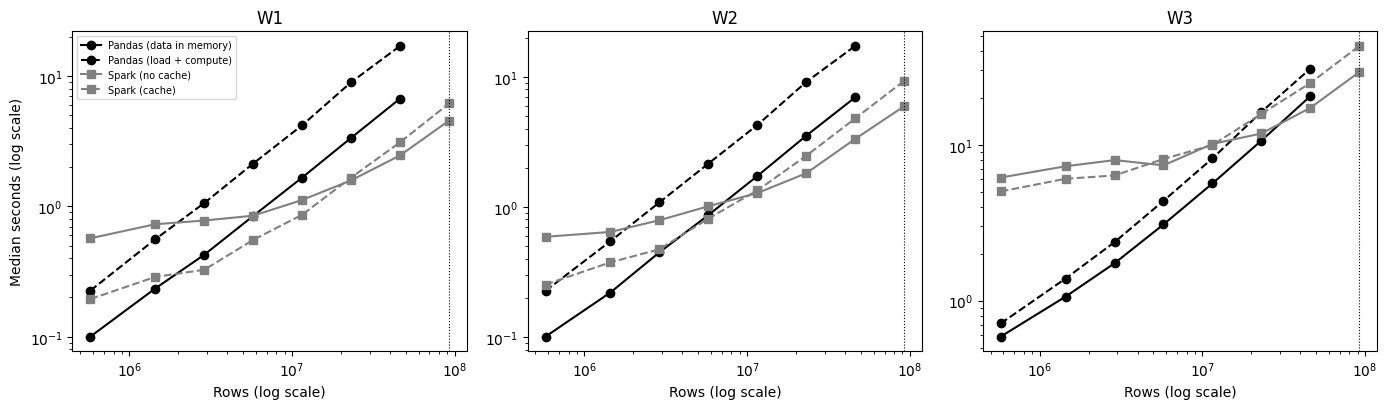

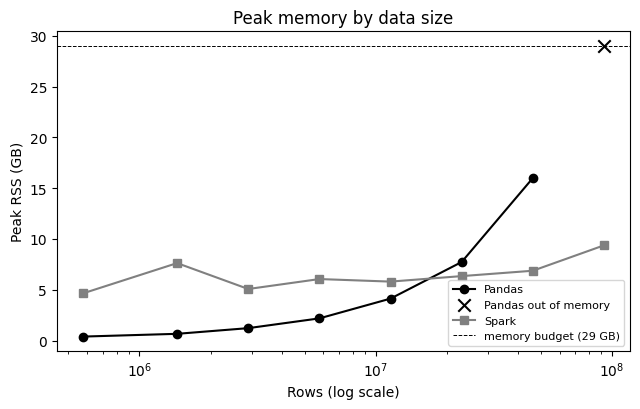

xong; kết quả trong /kaggle/working/results/perf


In [7]:
order = [s for s in SIZES]
xr = {s: DATA[s]["rows"] for s in order}
fig, axs = plt.subplots(1, 3, figsize=(14, 4.2), sharey=False)
for ax, w in zip(axs, ["W1", "W2", "W3"]):
    for (eng, meas, ls, mk, lab) in [("pandas", w, "-", "o", "Pandas (data in memory)"), ("pandas", f"{w}_cold", "--", "o", "Pandas (load + compute)"),
                                     ("spark", f"{w}_nocache", "-", "s", "Spark (no cache)"), ("spark", f"{w}_cache", "--", "s", "Spark (cache)")]:
        q = summ[(summ["engine"] == eng) & (summ["measure"] == meas)].copy()
        q["x"] = q["size"].map(xr); q = q.dropna(subset=["x"]).sort_values("x")
        if len(q):
            ax.plot(q["x"], q["median"], ls=ls, marker=mk, color="black" if eng == "pandas" else "grey", label=lab)
    for _, r in oom.iterrows():
        ax.axvline(xr.get(r["size"], np.nan), color="black", lw=.8, ls=":")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Rows (log scale)"); ax.set_title(w)
axs[0].set_ylabel("Median seconds (log scale)"); axs[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG}/perf_time_vs_rows.png", dpi=150)
if IN_NOTEBOOK:
    plt.show()
plt.close("all")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for eng, mk in [("pandas", "o"), ("spark", "s")]:
    q = mem[(mem["engine"] == eng) & (mem["size"].isin(order))].copy(); q["x"] = q["size"].map(xr); q = q.sort_values("x")
    ok_ = q[q["status"] == "ok"]; bad = q[~q["status"].isin(["ok", "not_run_after_oom"])]
    ax.plot(ok_["x"], ok_["peak_rss_gb"], marker=mk, color="black" if eng == "pandas" else "grey", label=eng.capitalize())
    if len(bad):
        ax.scatter(bad["x"], bad["peak_rss_gb"], marker="x", s=80, color="black", label=f"{eng.capitalize()} out of memory")
ax.axhline(BUDGET / 1e9, color="black", lw=.7, ls="--", label=f"memory budget ({BUDGET / 1e9:.0f} GB)")
ax.set_xscale("log"); ax.set_xlabel("Rows (log scale)"); ax.set_ylabel("Peak RSS (GB)"); ax.legend(fontsize=8)
ax.set_title("Peak memory by data size"); plt.tight_layout(); plt.savefig(f"{FIG}/perf_peak_memory.png", dpi=150)
if IN_NOTEBOOK:
    plt.show()
plt.close("all")
print("xong; kết quả trong", RES)